# Feature Spaces and Embeddings

1. Feature vectors and distances
2. PCA by hand (2D toy data)
3. PCA on real data: handwritten digits
4. Embeddings: words as vectors

You only need `numpy`, `matplotlib` and `scikit-learn`.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
plt.rcParams["figure.figsize"] = (6, 4)

## 1. Feature vectors and distances
Each row in a dataset is a **feature vector**. Here, each fruit is described by three features:
`[weight (g), sweetness, colour]`.

In [3]:
features = ["weight", "sweetness", "colour"]
apple1 = np.array([150, 11.2, 0.9])
apple2 = np.array([165, 10.8, 0.8])
orange = np.array([210,  8.1, 0.4])

print("apple1 is a vector with", apple1.shape[0], "dimensions:", apple1)

apple1 is a vector with 3 dimensions: [150.   11.2   0.9]


**Euclidean distance** = straight-line distance between two points.
**Cosine similarity** = how similar the *directions* are (1 = same direction, 0 = unrelated).

In [4]:
def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))      # same as np.linalg.norm(a - b)

def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

print("distance apple1-apple2:", round(euclidean(apple1, apple2), 2))
print("distance apple1-orange:", round(euclidean(apple1, orange), 2))

distance apple1-apple2: 15.01
distance apple1-orange: 60.08


⚠️ Notice that **weight** dominates the distance because it is measured in grams (big numbers).
That is why we **scale** features first (last week's topic):

In [5]:
data = np.array([apple1, apple2, orange])
scaled = StandardScaler().fit_transform(data)   # mean 0, std 1 per column
a1, a2, o = scaled

print("scaled distance apple1-apple2:", round(euclidean(a1, a2), 2))
print("scaled distance apple1-orange:", round(euclidean(a1, o), 2))

scaled distance apple1-apple2: 0.8
scaled distance apple1-orange: 4.0


### The feature space
With two features we can **plot** every fruit as a point. Similar fruits form clouds.

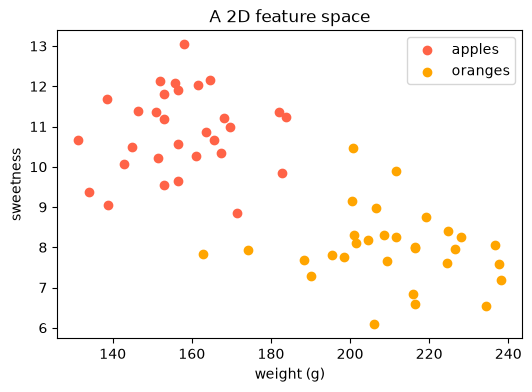

In [6]:
apples  = np.column_stack([np.random.normal(160, 15, 30), np.random.normal(11, 1.1, 30)])
oranges = np.column_stack([np.random.normal(210, 18, 30), np.random.normal(8, 1.0, 30)])

plt.scatter(apples[:, 0], apples[:, 1], label="apples", c="tomato")
plt.scatter(oranges[:, 0], oranges[:, 1], label="oranges", c="orange")
plt.xlabel("weight (g)")
plt.ylabel("sweetness")
plt.title("A 2D feature space")
plt.legend()
plt.show()

**Try it:** Add a new fruit, e.g. `mystery = np.array([175, 10.0])`. Plot it as a black `x`.
Which group is it closest to? Compute its distance to the *mean* apple and the *mean* orange.

In [7]:
# your code here

## 2. PCA by hand
PCA finds the directions where the data **varies the most**. We do it in four steps on 2D data,
so we can see what happens.

In [8]:
# correlated 2D data (a stretched, tilted cloud)
X = np.random.multivariate_normal(mean=[2, 3], cov=[[3, 2.2], [2.2, 2]], size=200)

# Step 1: center the data
X_centered = X - X.mean(axis=0)

# Step 2+3: the principal components are the eigenvectors of the covariance matrix
cov = np.cov(X_centered.T)
eigenvalues, eigenvectors = np.linalg.eigh(cov)

# sort from largest to smallest variance
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

print("variance along PC1, PC2:", eigenvalues.round(2))
print("explained variance ratio:", (eigenvalues / eigenvalues.sum()).round(3))

variance along PC1, PC2: [4.93 0.23]
explained variance ratio: [0.956 0.044]


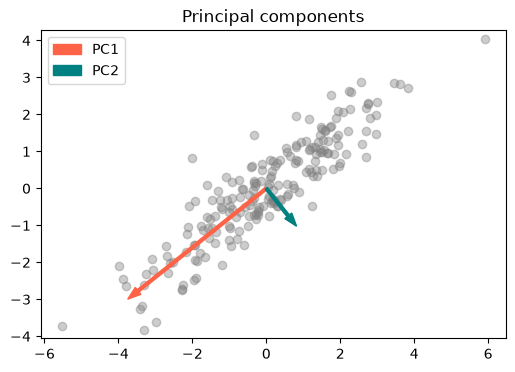

In [9]:
plt.scatter(X_centered[:, 0], X_centered[:, 1], alpha=0.4, c="gray")
for i, color in enumerate(["tomato", "teal"]):
    direction = eigenvectors[:, i] * np.sqrt(eigenvalues[i]) * 2
    plt.arrow(0, 0, *direction, width=0.08, color=color, label=f"PC{i+1}")
plt.axis("equal")
plt.legend()
plt.title("Principal components")
plt.show()

**Step 4: project.** Each point gets new coordinates along the components.
If we keep only PC1, our 2D data becomes 1D.

same result as sklearn: True


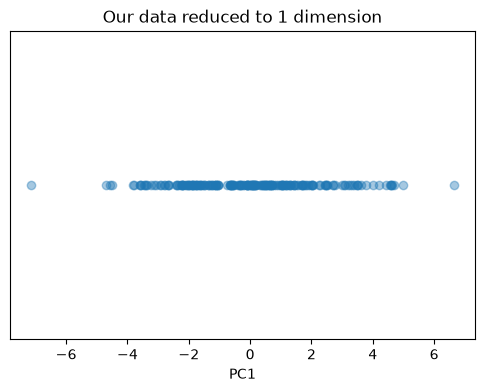

In [10]:
Z = X_centered @ eigenvectors          # coordinates in the PC system (still 2D)
z1 = Z[:, 0]                           # keep only PC1 -> 1D

# Compare with scikit-learn (the sign of a component can be flipped, that's fine)
Z_sklearn = PCA(n_components=2).fit_transform(X)
print("same result as sklearn:", np.allclose(np.abs(Z), np.abs(Z_sklearn)))

plt.scatter(z1, np.zeros_like(z1), alpha=0.4)
plt.yticks([])
plt.xlabel("PC1")
plt.title("Our data reduced to 1 dimension")
plt.show()

**Try it:** Change the covariance to `[[3, 0], [0, 3]]` (a round cloud) and run part 2 again.
What happens to the explained variance ratio? Why does PCA not help much here?

## 3. PCA on real data: handwritten digits
1797 images of digits, each 8×8 pixels = **64 features**.

data shape: (1797, 64)


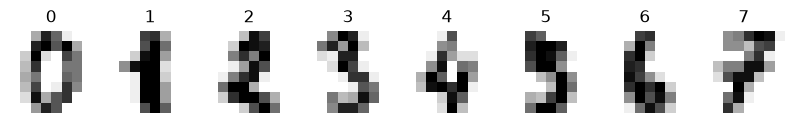

the first image as a feature vector:
 [ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]


In [11]:
digits = load_digits()
X, y = digits.data, digits.target
print("data shape:", X.shape)        # (samples, features)

fig, axes = plt.subplots(1, 8, figsize=(10, 2))
for ax, img, label in zip(axes, digits.images, y):
    ax.imshow(img, cmap="gray_r")
    ax.set_title(label)
    ax.axis("off")
plt.show()

print("the first image as a feature vector:\n", X[0])

### From 64D to 2D

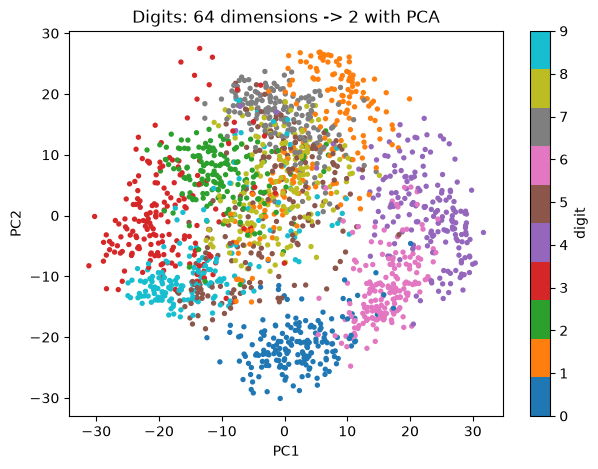

variance kept by 2 components: 0.285


In [12]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)          # note: labels y are NOT used!

plt.figure(figsize=(7, 5))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap="tab10", s=8)
plt.colorbar(scatter, label="digit")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Digits: 64 dimensions -> 2 with PCA")
plt.show()

print("variance kept by 2 components:", pca.explained_variance_ratio_.sum().round(3))

### How many components should we keep?

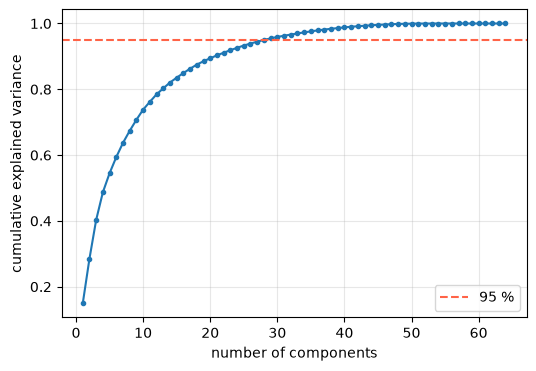

29 components keep 95 % of the variance


In [13]:
pca_full = PCA().fit(X)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)

plt.plot(range(1, 65), cumulative, marker=".")
plt.axhline(0.95, color="tomato", linestyle="--", label="95 %")
plt.xlabel("number of components")
plt.ylabel("cumulative explained variance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

k95 = np.argmax(cumulative >= 0.95) + 1
print(f"{k95} components keep 95 % of the variance")

### What is lost? Reconstruct images from k components
`inverse_transform` maps the compressed vectors back to 64 pixels.

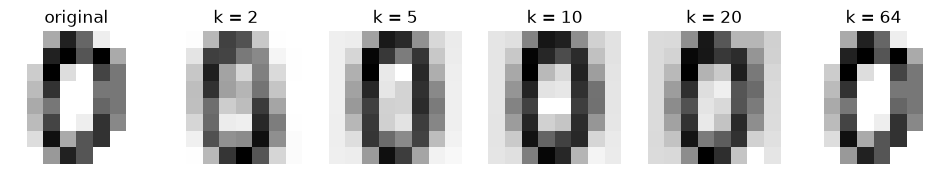

In [14]:
ks = [2, 5, 10, 20, 64]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(12, 2.2))
axes[0].imshow(X[0].reshape(8, 8), cmap="gray_r")
axes[0].set_title("original")
for ax, k in zip(axes[1:], ks):
    p = PCA(n_components=k).fit(X)
    restored = p.inverse_transform(p.transform(X[:1]))
    ax.imshow(restored.reshape(8, 8), cmap="gray_r")
    ax.set_title(f"k = {k}")
for ax in axes:
    ax.axis("off")
plt.show()

### Bonus: t-SNE (non-linear, only for visualisation)
This may take a few seconds.

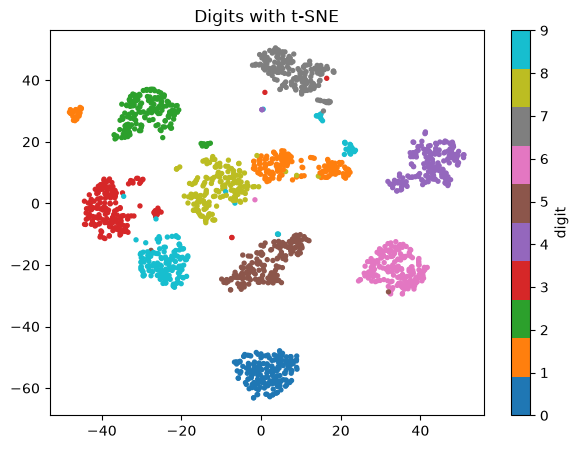

In [15]:
from sklearn.manifold import TSNE

X_tsne = TSNE(n_components=2, random_state=0).fit_transform(X)
plt.figure(figsize=(7, 5))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap="tab10", s=8)
plt.colorbar(label="digit")
plt.title("Digits with t-SNE")
plt.show()

**Try it:**
1. Which digits overlap the most in the PCA plot? Does t-SNE separate them better?
2. Train a classifier (e.g. `KNeighborsClassifier`) on the original 64 features and on 10 PCA components.
   Compare accuracy and training time.

In [16]:
# your code here

## 4. Embeddings: words as vectors
An **embedding** is a short, dense vector learned so that similar things are close.
Real embeddings have hundreds of dimensions and are learned from huge amounts of text.
Here we use **hand-made 4D vectors** so we can see the idea.

Dimensions (only for intuition — real embeddings have no readable meaning per dimension):
`[royalty, male, female, animal]`

In [17]:
words = {
    "king":   np.array([0.95, 0.90, 0.05, 0.02]),
    "queen":  np.array([0.95, 0.05, 0.90, 0.02]),
    "man":    np.array([0.10, 0.92, 0.08, 0.05]),
    "woman":  np.array([0.10, 0.06, 0.94, 0.05]),
    "prince": np.array([0.80, 0.85, 0.05, 0.03]),
    "cat":    np.array([0.05, 0.40, 0.45, 0.95]),
    "dog":    np.array([0.05, 0.50, 0.40, 0.97]),
}

print("cat vs dog:  ", round(cosine_similarity(words["cat"], words["dog"]), 3))
print("cat vs king: ", round(cosine_similarity(words["cat"], words["king"]), 3))

cat vs dog:   0.996
cat vs king:  0.305


### Nearest neighbours

In [18]:
def most_similar(vector, exclude=()):
    scores = {w: cosine_similarity(vector, v) for w, v in words.items() if w not in exclude}
    return sorted(scores.items(), key=lambda item: item[1], reverse=True)

for word, score in most_similar(words["king"], exclude=["king"]):
    print(f"{word:7s} {score:.3f}")

prince  0.998
man     0.762
queen   0.579
dog     0.352
cat     0.305
woman   0.159


### Vector arithmetic: king − man + woman ≈ ?

In [19]:
result = words["king"] - words["man"] + words["woman"]
best_word, best_score = most_similar(result, exclude=["king", "man", "woman"])[0]
print(f"closest word: {best_word} (cosine similarity {best_score:.3f})")

closest word: queen (cosine similarity 1.000)


### Visualise the embeddings with PCA (4D -> 2D)

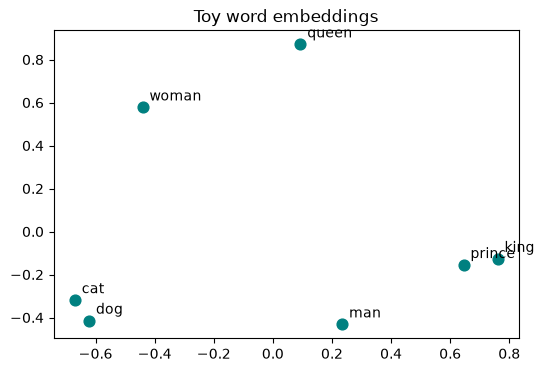

In [20]:
names = list(words)
vectors = np.array([words[w] for w in names])
points = PCA(n_components=2).fit_transform(vectors)

plt.scatter(points[:, 0], points[:, 1], s=60, c="teal")
for name, (px, py) in zip(names, points):
    plt.annotate(name, (px, py), textcoords="offset points", xytext=(5, 5))
plt.title("Toy word embeddings")
plt.show()

**Try it:** Add `"princess"`, `"kitten"` and `"puppy"` with your own vectors.
Do they land where you expect? What is the closest word to `"prince" - "man" + "woman"`?

In [21]:
# your code here

### Optional: real sentence embeddings
Requires `pip install sentence-transformers` and an internet connection the first time (downloads a small model, ~90 MB).
The cell is skipped if the library is not installed.

In [24]:
try:
    from sentence_transformers import SentenceTransformer
    model = SentenceTransformer("all-MiniLM-L6-v2")
    sentences = [
        "The cat sits on the mat.",
        "A kitten is sleeping on the rug.",
        "The stock market fell today.",
        "Shares dropped sharply this morning."
    ]
    emb = model.encode(sentences)
    print("each sentence ->", emb.shape[1], "dimensions")
    for i in range(len(sentences)):
        for j in range(i + 1, len(sentences)):
            print(f"{cosine_similarity(emb[i], emb[j]):.2f}  {sentences[i]!r} vs {sentences[j]!r}")
except ImportError:
    print("sentence-transformers is not installed - skipping this optional part.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

each sentence -> 384 dimensions
0.57  'The cat sits on the mat.' vs 'A kitten is sleeping on the rug.'
0.10  'The cat sits on the mat.' vs 'The stock market fell today.'
0.04  'The cat sits on the mat.' vs 'Shares dropped sharply this morning.'
0.09  'The cat sits on the mat.' vs 'The King is sleepy'
0.07  'The cat sits on the mat.' vs 'The Prince is tired'
0.05  'A kitten is sleeping on the rug.' vs 'The stock market fell today.'
-0.03  'A kitten is sleeping on the rug.' vs 'Shares dropped sharply this morning.'
0.18  'A kitten is sleeping on the rug.' vs 'The King is sleepy'
0.22  'A kitten is sleeping on the rug.' vs 'The Prince is tired'
0.63  'The stock market fell today.' vs 'Shares dropped sharply this morning.'
0.02  'The stock market fell today.' vs 'The King is sleepy'
0.08  'The stock market fell today.' vs 'The Prince is tired'
-0.01  'Shares dropped sharply this morning.' vs 'The King is sleepy'
0.02  'Shares dropped sharply this morning.' vs 'The Prince is tired'
0.63  'T

## Summary
- A data point is a **vector**; features are the axes of a **feature space**.
- **Distance** (Euclidean or cosine) measures similarity — scale your features first.
- **PCA** finds the directions of largest variance and reduces dimensions, great for plots and compression.
- **Embeddings** are learned vectors where similar meaning means nearby points.